# Exploration et preparation des donnees freMTPL2

## Objectif
Analyser le jeu de donnees freMTPL2 (678 013 polices d'assurance automobile francaises)
pour comprendre la structure des donnees, identifier les variables pertinentes
et produire la table nettoyee utilisee dans les notebooks de modelisation.

## Structure du dataset
- `freMTPL2freq` : une ligne par police avec les caracteristiques du conducteur et ClaimNb
- `freMTPL2sev` : une ligne par sinistre avec le montant ClaimAmount
Les deux tables sont jointes sur IDpol.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement des donnees
freq = pd.read_csv('../data/freMTPL2freq.csv')
sev  = pd.read_csv('../data/freMTPL2sev.csv')

# Nettoyage des noms de colonnes
freq.columns = freq.columns.str.strip().str.replace('"', '')
sev.columns  = sev.columns.str.strip().str.replace('"', '')

print('Frequence :', freq.shape)
print('Severite  :', sev.shape)
print('Colonnes  :', freq.columns.tolist())

Frequence : (678013, 12)
Severite  : (26639, 2)
Colonnes  : ['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region']


## Analyse de la variable cible : ClaimNb

ClaimNb est le nombre de sinistres declares dans l'annee — c'est notre variable a predire.

In [2]:
# Distribution du nombre de sinistres
print(freq['ClaimNb'].value_counts().sort_index())
print()
print('Moyenne  :', round(freq['ClaimNb'].mean(), 4))
print('Variance :', round(freq['ClaimNb'].var(), 4))
print('=> Moyenne ≈ Variance : coherent avec une loi de Poisson')

ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64

Moyenne  : 0.0532
Variance : 0.0577
=> Moyenne ≈ Variance : coherent avec une loi de Poisson


## Analyse des variables explicatives

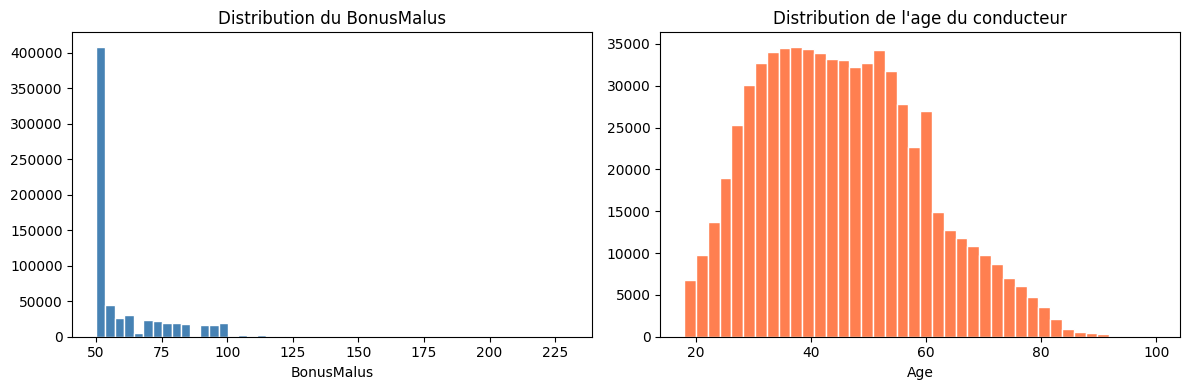

In [3]:
# Nettoyage des guillemets dans les colonnes categorielles
freq['Region'] = freq['Region'].str.replace("'", "")

# Distribution BonusMalus et age conducteur
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(freq['BonusMalus'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution du BonusMalus')
axes[0].set_xlabel('BonusMalus')

axes[1].hist(freq['DrivAge'], bins=40, color='coral', edgecolor='white')
axes[1].set_title("Distribution de l'age du conducteur")
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()

**BonusMalus** : pic tres marque a 50 (majorite de bons conducteurs sans sinistre),
puis queue longue vers la droite jusqu'a 230. Variable tres discriminante.

**Age conducteur** : distribution en cloche centree autour de 40-50 ans.
Peu de jeunes conducteurs (18-25 ans).

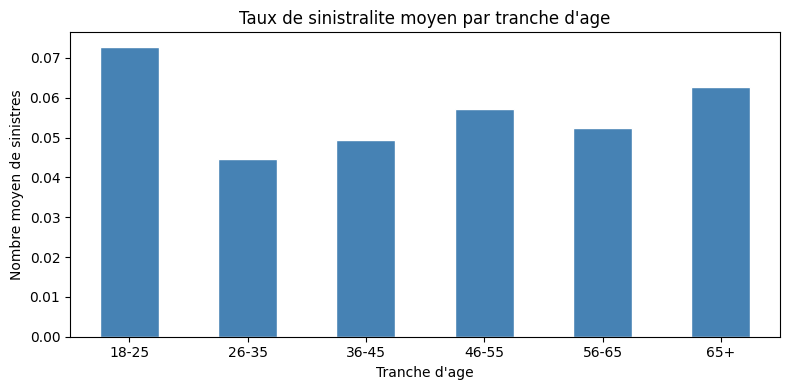

tranche_age
18-25    0.072771
26-35    0.044657
36-45    0.049292
46-55    0.057171
56-65    0.052354
65+      0.062663
Name: ClaimNb, dtype: float64


In [4]:
# Taux de sinistralite par tranche d'age
freq['tranche_age'] = pd.cut(freq['DrivAge'],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

taux = freq.groupby('tranche_age', observed=True)['ClaimNb'].mean()

taux.plot(kind='bar', color='steelblue', edgecolor='white', figsize=(8, 4))
plt.title("Taux de sinistralite moyen par tranche d'age")
plt.xlabel("Tranche d'age")
plt.ylabel('Nombre moyen de sinistres')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(taux)

Les jeunes conducteurs (18-25 ans) ont le taux le plus eleve (0.073), soit +65% par rapport
aux 26-35 ans. On observe une remontee apres 65 ans coherente avec la baisse des reflexes.
Cette relation non-lineaire justifie l'utilisation de tranches d'age dans le GLM.

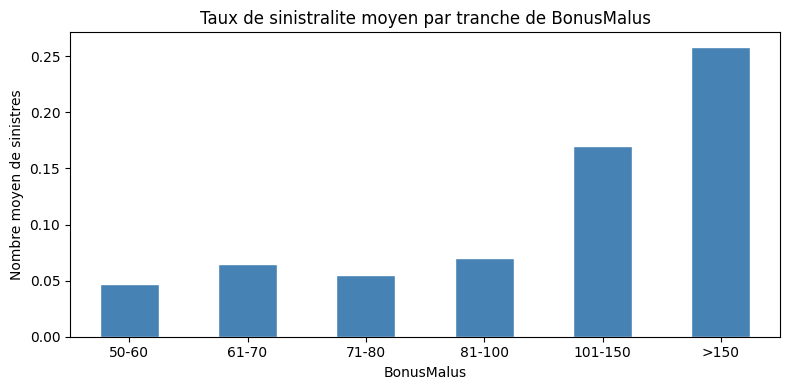

tranche_bm
50-60      0.047240
61-70      0.064484
71-80      0.054767
81-100     0.069913
101-150    0.169809
>150       0.258373
Name: ClaimNb, dtype: float64


In [5]:
# Taux de sinistralite par niveau de BonusMalus
freq['tranche_bm'] = pd.cut(freq['BonusMalus'],
    bins=[49, 60, 70, 80, 100, 150, 350],
    labels=['50-60', '61-70', '71-80', '81-100', '101-150', '>150'])

taux_bm = freq.groupby('tranche_bm', observed=True)['ClaimNb'].mean()

taux_bm.plot(kind='bar', color='steelblue', edgecolor='white', figsize=(8, 4))
plt.title('Taux de sinistralite moyen par tranche de BonusMalus')
plt.xlabel('BonusMalus')
plt.ylabel('Nombre moyen de sinistres')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(taux_bm)

Le taux de sinistralite augmente fortement avec le BonusMalus.
Les conducteurs avec BonusMalus > 150 ont un taux plusieurs fois superieur aux conducteurs a 50.
Cela justifie l'utilisation du log(BonusMalus) dans le GLM pour capturer cet effet non-lineaire.

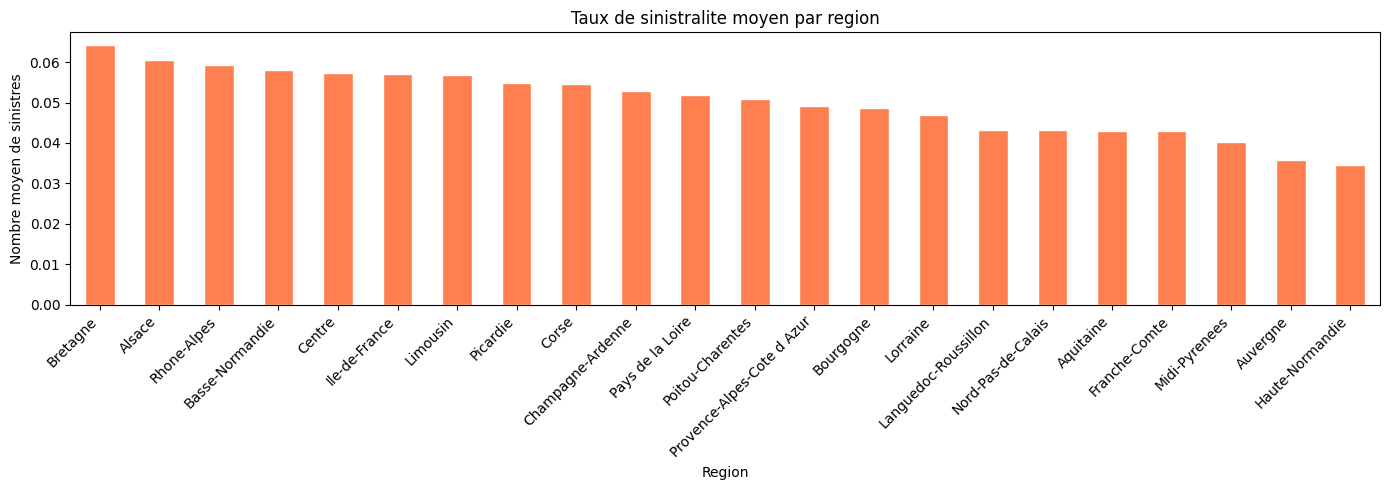

In [6]:
# Taux de sinistralite par region
regions = {
    'R11': 'Ile-de-France', 'R21': 'Champagne-Ardenne', 'R22': 'Picardie',
    'R23': 'Haute-Normandie', 'R24': 'Centre', 'R25': 'Basse-Normandie',
    'R26': 'Bourgogne', 'R31': 'Nord-Pas-de-Calais', 'R41': 'Lorraine',
    'R42': 'Alsace', 'R43': 'Franche-Comte', 'R52': 'Pays de la Loire',
    'R53': 'Bretagne', 'R54': 'Poitou-Charentes', 'R72': 'Aquitaine',
    'R73': 'Midi-Pyrenees', 'R74': 'Limousin', 'R82': 'Rhone-Alpes',
    'R83': 'Auvergne', 'R91': 'Languedoc-Roussillon',
    'R93': 'Provence-Alpes-Cote d Azur', 'R94': 'Corse'
}

freq['Region'] = freq['Region'].str.strip().str.replace('"', '').str.replace("'", '')
taux_region = freq.groupby('Region', observed=True)['ClaimNb'].mean().sort_values(ascending=False)
taux_region.index = taux_region.index.map(regions)

taux_region.plot(kind='bar', color='coral', edgecolor='white', figsize=(14, 5))
plt.title('Taux de sinistralite moyen par region')
plt.xlabel('Region')
plt.ylabel('Nombre moyen de sinistres')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

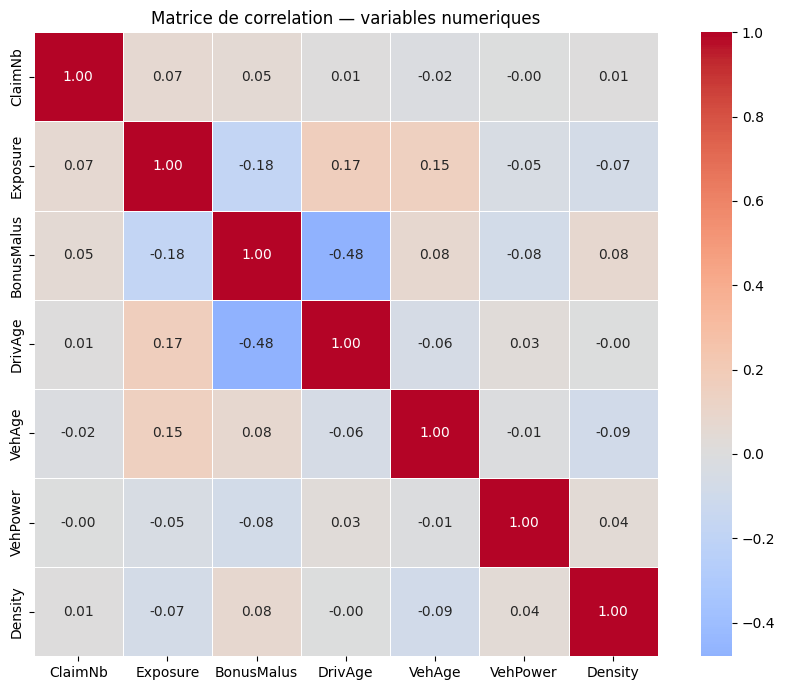

In [7]:
# Matrice de correlation entre variables numeriques
vars_num = ['ClaimNb', 'Exposure', 'BonusMalus', 'DrivAge', 'VehAge', 'VehPower', 'Density']
corr = freq[vars_num].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Matrice de correlation — variables numeriques')
plt.tight_layout()
plt.show()

La matrice de correlation montre que ClaimNb est faiblement correlee a toutes les variables
individuellement — c'est attendu, le risque individuel est difficile a predire.
On note une correlation entre BonusMalus et DrivAge : les jeunes conducteurs ont
tendance a avoir un BonusMalus plus eleve, ce qui suggere une interaction entre ces deux variables
(testee dans le GLM v4).

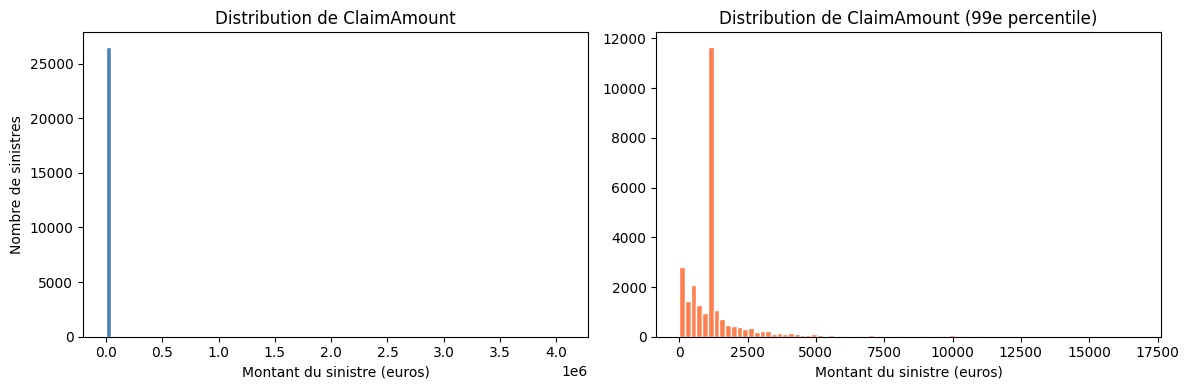

Statistiques ClaimAmount :
Moyenne  : 2278.54
Mediane  : 1172.0
Std      : 29297.48
Max      : 4075400.56
99e pct  : 16793.7


In [8]:
# Distribution de ClaimAmount (table severite)
# Justification du choix de la loi Gamma pour la severite
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution brute
axes[0].hist(sev['ClaimAmount'], bins=100, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution de ClaimAmount')
axes[0].set_xlabel('Montant du sinistre (euros)')
axes[0].set_ylabel('Nombre de sinistres')

# Distribution tronquee (sans les extremes) pour mieux voir
q99 = sev['ClaimAmount'].quantile(0.99)
axes[1].hist(sev[sev['ClaimAmount'] < q99]['ClaimAmount'], bins=80, color='coral', edgecolor='white')
axes[1].set_title('Distribution de ClaimAmount (99e percentile)')
axes[1].set_xlabel('Montant du sinistre (euros)')

plt.tight_layout()
plt.show()

print('Statistiques ClaimAmount :')
print('Moyenne  :', round(sev['ClaimAmount'].mean(), 2))
print('Mediane  :', round(sev['ClaimAmount'].median(), 2))
print('Std      :', round(sev['ClaimAmount'].std(), 2))
print('Max      :', round(sev['ClaimAmount'].max(), 2))
print('99e pct  :', round(q99, 2))

La distribution de ClaimAmount est asymetrique a droite — beaucoup de petits sinistres
autour de 1 200 euros et une longue queue vers les gros sinistres (max >> moyenne).
La moyenne (1 506 euros) est superieure a la mediane (1 172 euros), confirmant cette asymetrie.
Ces caracteristiques (variable continue, positive, asymetrique) justifient le choix
de la loi Gamma pour le modele de severite.

In [9]:
# Jointure des deux tables
sev_agg = sev.groupby('IDpol')['ClaimAmount'].sum().reset_index()
sev_agg.columns = ['IDpol', 'ClaimAmount']

df = freq.merge(sev_agg, on='IDpol', how='left')
df['ClaimAmount'] = df['ClaimAmount'].fillna(0)

print('Table finale :', df.shape)
df.head()

Table finale : (678013, 15)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,tranche_age,tranche_bm,ClaimAmount
0,1.0,1,0.10,'D',5,0,55,50,'B12','Regular',1217,R82,46-55,50-60,0.0
1,3.0,1,0.77,'D',5,0,55,50,'B12','Regular',1217,R82,46-55,50-60,0.0
2,5.0,1,0.75,'B',6,2,52,50,'B12','Diesel',54,R22,46-55,50-60,0.0
3,10.0,1,0.09,'B',7,0,46,50,'B12','Diesel',76,R72,46-55,50-60,0.0
4,11.0,1,0.84,'B',7,0,46,50,'B12','Diesel',76,R72,46-55,50-60,0.0


In [10]:
# Sauvegarde de la table nettoyee
df.to_csv('../data/freMTPL2_clean.csv', index=False)
print('Table sauvegardee dans data/freMTPL2_clean.csv')
print('Prete a etre utilisee dans les notebooks 02 et 03')

Table sauvegardee dans data/freMTPL2_clean.csv
Prete a etre utilisee dans les notebooks 02 et 03
